# Dynamic case generation (offshore-waves forcing)

Workflow:

1. Load **goals** from the case JSON → `simulations.goals_file`.
2. Open a **processed offshore-waves** zarr (`offshore_waves` in the case JSON).
3. Build SnapWave boundary forcing per timestep (`hs`, `tp`, `wd`, `ds`).
4. Run cases (optional) and postprocess to a single time-series NetCDF.

Processed offshore data must use dims `(time, goal)` with bulk variables
`hs`, `tp`, `dir`, `spr` (see `07_Download_Process_WHACS.ipynb`).

In [1]:
from utils.config import (
    PATHS,
    SIMULATIONS,
    get_offshore_wave,
    goals_for_snapwave,
    load_goals,
    open_offshore_waves,
    resolve,
)
from utils.simulation.offshore_forcing import boundary_parameters
from utils.simulation.snapwave_wrappers import SnapWaveDynamicModelWrapper

## Configuration

In [2]:
offshore_name = "WHACS"  # must match an entry in the case JSON → offshore_waves
period = "2017"  # time slice passed to xarray .sel(time=...)

offshore_entry = get_offshore_wave(offshore_name)
templates_dir = resolve(SIMULATIONS["dynamic_templates"])
cases_dir = resolve(SIMULATIONS["dynamic_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])
offshore_path = resolve(offshore_entry["data_path"])
raw_goals = load_goals()

print(f"offshore  : {offshore_name} → {offshore_path}")
print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"period    : {period}")

offshore  : WHACS → /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/WHACS/processed/NewSouthWales_WHACS_goal.zarr
goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/Goals/NewSouthWales_Goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/templates-dynamic
cases     : /hyglowdata/NewSouthWales/SnapWave_CASES_Dynamic
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/inputs/GRID/NewSouthWales_mesh.nc
period    : 2017


## Offshore waves → boundary forcing

In [3]:
offshore_ds = open_offshore_waves(entry=offshore_entry).sel(time=period).load()
offshore_ds

<xarray.Dataset> Size: 37MB
Dimensions:   (time: 8760, goal: 26)
Coordinates:
  * time      (time) datetime64[ns] 70kB 2017-01-01 ... 2017-12-31T23:00:00
  * goal      (goal) int64 208B 1 2 3 4 5 6 7 8 9 ... 18 19 20 21 22 23 24 25 26
    seapoint  (goal) int64 208B 923284 937305 937042 ... 930128 929894 922215
Data variables: (12/20)
    dir       (time, goal) float64 2MB 48.3 32.3 24.7 19.1 ... 58.2 66.4 161.3
    hs        (time, goal) float64 2MB 1.122 1.402 1.51 ... 1.192 1.24 1.256
    pdir0     (time, goal) float64 2MB 23.5 356.5 352.2 ... 187.8 193.4 192.8
    pdir1     (time, goal) float64 2MB 72.7 72.0 64.2 164.4 ... 27.0 24.4 31.5
    pdir2     (time, goal) float64 2MB 142.1 163.8 164.1 ... 193.7 231.3 27.4
    pdir3     (time, goal) float64 2MB 40.9 38.7 35.9 nan ... 27.9 25.9 60.0
    ...        ...
    ptp0      (time, goal) float64 2MB 5.46 5.08 5.25 5.78 ... 7.78 14.43 13.48
    ptp1      (time, goal) float64 2MB 6.46 6.44 6.28 10.86 ... 6.19 6.24 6.33
    ptp2      (time, goal) float64 2MB 10.98 11.09 11.01 9.9 ... 14.44 11.9 10.5
    ptp3      (time, goal) float64 2MB 9.61 9.57 9.66 nan ... 10.33 10.56 12.18
    spr       (time, goal) float64 2MB 33.9 52.7 50.8 46.9 ... 71.0 76.9 70.8
    tp        (time, goal) float64 2MB 5.814 5.405 5.495 ... 6.329 6.369 6.494
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [4]:
metamodel_parameters = boundary_parameters(offshore_ds)
list(metamodel_parameters.keys())

['hs_goals', 'tp_goals', 'dir_goals', 'spr_goals', 'tref']

In [5]:
import numpy as np

n_cases = len(metamodel_parameters["tref"])
metamodel_parameters["save_map"] = np.random.choice(
    [True, False], size=n_cases, p=[0.05, 0.95]
).tolist()
sum(metamodel_parameters["save_map"]), n_cases

(434, 8760)

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + observed direction-range bars per goal; right side = text summary.
Each case is one timestep with **all goals forced** on the boundary.
Review this before `build_cases()`.

In [6]:
wrapper = SnapWaveDynamicModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-08-04 13:09:36,329 - SnapWaveDynamicModelWrapper - WARNING - Parameter hs_goals is not in the default_parameters
2026-08-04 13:09:36,330 - SnapWaveDynamicModelWrapper - WARNING - Parameter tp_goals is not in the default_parameters
2026-08-04 13:09:36,330 - SnapWaveDynamicModelWrapper - WARNING - Parameter dir_goals is not in the default_parameters
2026-08-04 13:09:36,331 - SnapWaveDynamicModelWrapper - WARNING - Parameter spr_goals is not in the default_parameters
2026-08-04 13:09:36,332 - SnapWaveDynamicModelWrapper - WARNING - Parameter tref is not in the default_parameters
2026-08-04 13:09:36,332 - SnapWaveDynamicModelWrapper - WARNING - Parameter save_map is not in the default_parameters


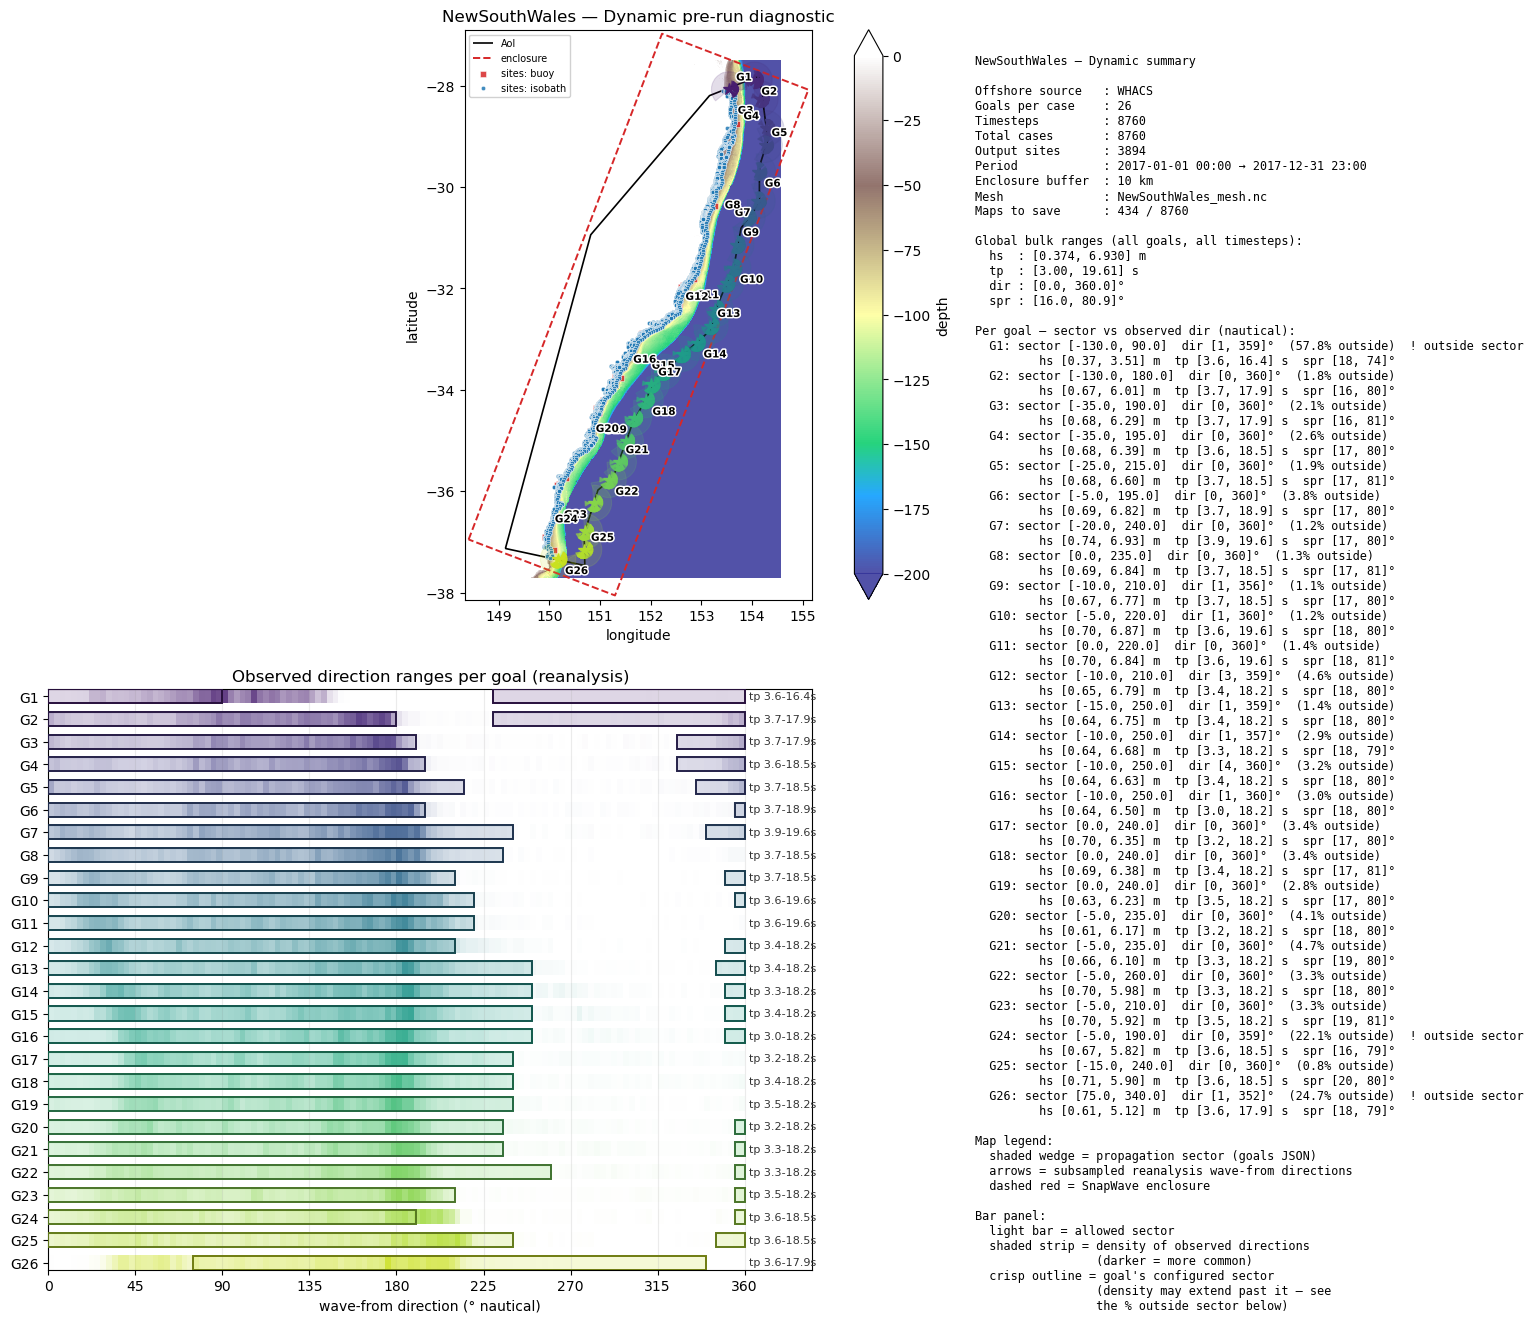

In [7]:
fig = wrapper.plot_configuration(offshore=offshore_ds, offshore_name=offshore_name)
# fig.savefig("dynamic_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [8]:
wrapper.load_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [9]:
wrapper.cases_dir_to_txt()

'/hyglowdata/NewSouthWales/SnapWave_CASES_Dynamic/case_dirs.txt'

In [10]:
# wrapper.run_cases_in_background(launcher="default", num_workers=1)

In [19]:
wrapper.monitor_cases(value_counts="simple")

Status     
NOT STARTED    8624
FINISHED        136
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map when `save_map=True` for that timestep
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

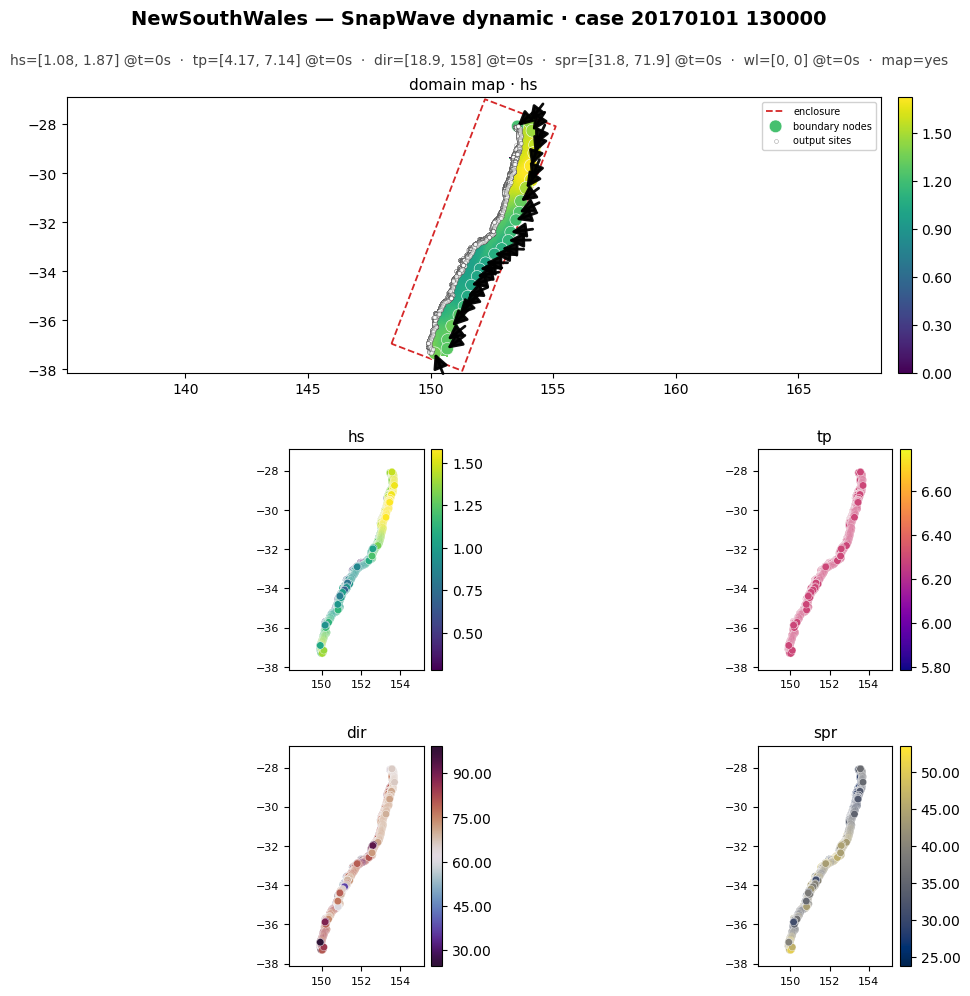

In [ ]:
from utils.viz.snapwave_case_plots import CasePlotStyle

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
wrapper.plot_case(
    "/hyglowdata/NewSouthWales/SnapWave_CASES_Dynamic/20170101 130000", style=style
);

In [ ]:
result = wrapper.postprocess_cases()
out_nc = cases_dir / f"Dynamic_Cases_{offshore_name}_{period.replace('-', '')}.nc"
result.to_netcdf(out_nc)

In [ ]:
import xarray as xr

xr.open_dataset(out_nc).load()